# Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data


### Before You Start
- You already know the models, scaling, splitting and cross-validation from Labs 3-8. This lab does not re-teach them.
- Every task ends with a question about **your own results**. A table or plot without a written interpretation earns no marks.
- Use `SEED = 42` everywhere. **Golden rule:** anything that learns from data (scaler, imputer, resampler, threshold) is learned from the **training data only**.
- Install once if needed: `pip install imbalanced-learn`


---

## Part 0 — Setup and the Data
A hospital wants to flag patients at risk of stroke from routine information. Target: `stroke` (1 = had a stroke, 0 = did not).

**What to do:**
1. Import everything you need (including `imblearn`) and set `SEED = 42`.
2. Load the CSV. Report the shape, the columns with missing values, the value counts of `gender`, and the number of patients with `stroke = 1` and `stroke = 0` (count and %).
3. Clean: remove the identifier column; remove any `gender` category with too few rows to learn or test; apply categorical encoding (`pd.get_dummies`) to the text columns.
4. Split 80/20 with `stratify=y`, `random_state=SEED`. Fill missing numeric values with a median learned from the **train** set only. Make a scaled copy (`StandardScaler` fitted on train) for Logistic Regression.
5. Report the number of stroke cases in the train and in the test set.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    learning_curve, cross_val_predict
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler


SEED = 42


In [ ]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print(f"Shape: {df.shape}")
print(f"\nMissing values:\n{df.isnull().sum()[df.isnull().sum() > 0]}")
print(f"\nGender counts:\n{df['gender'].value_counts()}")

stroke_counts = df['stroke'].value_counts()
stroke_pct = df['stroke'].value_counts(normalize=True) * 100
print(f"\nStroke = 1: {stroke_counts.get(1, 0)} ({stroke_pct.get(1, 0):.2f}%)")
print(f"Stroke = 0: {stroke_counts.get(0, 0)} ({stroke_pct.get(0, 0):.2f}%)")

Shape: (5110, 12)

Missing values:
bmi    201
dtype: int64

Gender counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke = 1: 249 (4.87%)
Stroke = 0: 4861 (95.13%)


In [ ]:
df = df.drop(columns=['id'], errors='ignore')
df = df[df['gender'] != 'Other']

X = pd.get_dummies(df.drop(columns=['stroke']), drop_first=True)
y = df['stroke']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

imputer = SimpleImputer(strategy='median')
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_imputed), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_imputed), columns=X_test.columns, index=X_test.index)

print(f"\nStroke cases in Train: {y_train.sum()}")
print(f"Stroke cases in Test: {y_test.sum()}")


Stroke cases in Train: 199
Stroke cases in Test: 50


**Question 0.1:** In 2–3 lines: how imbalanced is the data? Why did we use `stratify=y`, and what could go wrong with only a few stroke cases in the test set?

**Your answer:**

The data is severely imbalanced, with strokes making up less than 5% of the total cases. We used stratify=y to ensure this 5% ratio is identically preserved in both the training and testing sets. If we didn't stratify, a random split might assign almost zero stroke cases to the test set, making it statistically impossible to evaluate how well the model actually detects strokes.


---

## Part 1 — The Accuracy Trap
**Objective:** show that a model can have excellent accuracy and still be useless.
1. Build a baseline that always predicts the majority class (`DummyClassifier(strategy='most_frequent')`). Report accuracy.
2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC AUC and PR AUC (average precision) on the test set, and print the confusion matrix.
3. Write a helper function that takes a model and train/test data and returns these six metrics (you will reuse it all lab).

In [ ]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    return {
        'Accuracy': round(accuracy_score(y_te, y_pred), 4),
        'Precision': round(precision_score(y_te, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_te, y_pred, zero_division=0), 4),
        'F1': round(f1_score(y_te, y_pred, zero_division=0), 4),
        'ROC AUC': round(roc_auc_score(y_te, y_prob), 4),
        'PR AUC': round(average_precision_score(y_te, y_prob), 4)
    }

dummy = DummyClassifier(strategy='most_frequent', random_state=SEED)
dummy.fit(X_train_scaled, y_train)
dummy_acc = accuracy_score(y_test, dummy.predict(X_test_scaled))
print(f"Dummy Baseline Accuracy: {dummy_acc:.4f}")


Dummy Baseline Accuracy: 0.9511


In [ ]:
lr = LogisticRegression(random_state=SEED)
lr_metrics = evaluate_model(lr, X_train_scaled, y_train, X_test_scaled, y_test)

print("Logistic Regression Test Metrics:")
for k, v in lr_metrics.items():
    print(f"  {k}: {v}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr.predict(X_test_scaled)))

Logistic Regression Test Metrics:
  Accuracy: 0.9521
  Precision: 1.0
  Recall: 0.02
  F1: 0.0392
  ROC AUC: 0.8394
  PR AUC: 0.2692

Confusion Matrix:
[[972   0]
 [ 49   1]]


**Question 1.1:** Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?

**Question 1.2:** Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?

**Your answer:**

1.1: Both the Dummy Classifier and Logistic Regression achieve roughly 95.1% accuracy (0.9511 vs 0.9521). This proves that accuracy is completely misleading on imbalanced data—a model can look 95% accurate just by guessing "no stroke" for everyone while failing to catch almost all actual strokes.  

1.2: A false negative (49 patients in the confusion matrix) means sending a high-risk patient home telling them they are fine, leading to an unprevented stroke. Because our Recall is practically zero (0.0200, catching only 1 out of 50 strokes), we must trust Recall, PR AUC, and ROC AUC instead of accuracy to judge whether the model actually identifies sick patients.   

---

## Part 2 — Underfitting, Overfitting, Bias and Variance
Use **ROC AUC** (not accuracy) as the score from now on.

### Task 2.1 — Validation curve
For `max_depth` = 1, 2, …, 15 and `None`, record the train ROC AUC and the 5-fold stratified CV ROC AUC (train data only). Plot both curves on one chart (labels, title, legend) and report the best depth by CV AUC.

Best max_depth by CV AUC: 4 (CV AUC = 0.8180, Train AUC = 0.8580)
Depth 1    -> Train AUC: 0.7171, CV AUC: 0.7317
Depth None -> Train AUC: 1.0000, CV AUC: 0.5644


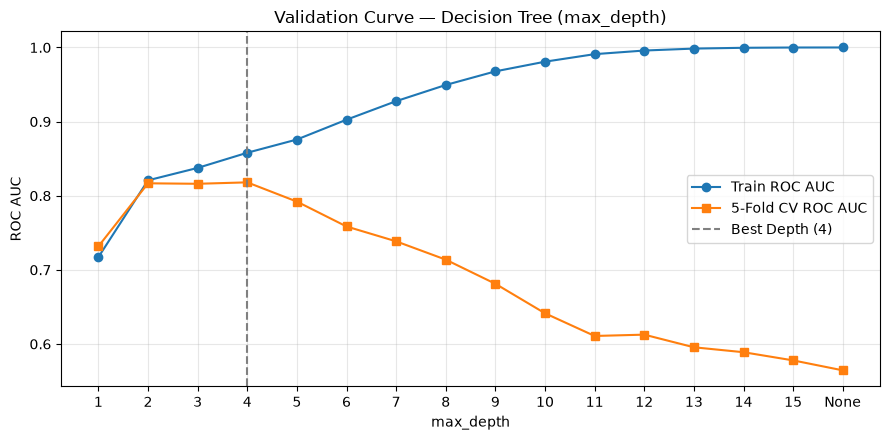

In [ ]:
depths = list(range(1, 16)) + [None]
depth_labels = [str(d) for d in depths]

train_aucs, cv_aucs = [], []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    tree.fit(X_train_imputed, y_train)

    tr_prob = tree.predict_proba(X_train_imputed)[:, 1]
    train_aucs.append(roc_auc_score(y_train, tr_prob))
    
    cv_score = cross_val_score(tree, X_train_imputed, y_train, cv=cv, scoring='roc_auc').mean()
    cv_aucs.append(cv_score)

best_idx = int(np.argmax(cv_aucs))
print(f"Best max_depth by CV AUC: {depths[best_idx]} (CV AUC = {cv_aucs[best_idx]:.4f}, Train AUC = {train_aucs[best_idx]:.4f})")
print(f"Depth 1    -> Train AUC: {train_aucs[0]:.4f}, CV AUC: {cv_aucs[0]:.4f}")
print(f"Depth None -> Train AUC: {train_aucs[-1]:.4f}, CV AUC: {cv_aucs[-1]:.4f}")

plt.figure(figsize=(9, 4.5))
plt.plot(depth_labels, train_aucs, marker='o', label='Train ROC AUC')
plt.plot(depth_labels, cv_aucs, marker='s', label='5-Fold CV ROC AUC')
plt.axvline(depth_labels[best_idx], color='gray', linestyle='--', label=f'Best Depth ({depths[best_idx]})')
plt.xlabel('max_depth')
plt.ylabel('ROC AUC')
plt.title('Validation Curve — Decision Tree (max_depth)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Task 2.2 — Learning curves
Use `learning_curve` (`scoring='roc_auc'`, train sizes 20%→100%) for a tree with `max_depth=1` and a tree with `max_depth=None`. Plot train and CV AUC against the number of training rows, side by side.

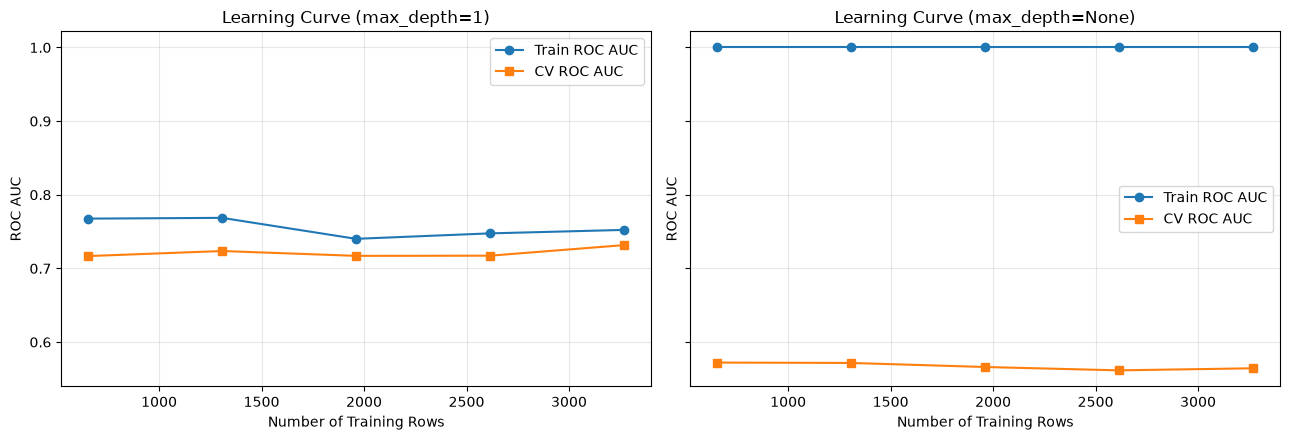

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, d in zip(axes, [1, None]):
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    sizes, tr_scores, val_scores = learning_curve(
        tree, X_train_imputed, y_train,
        train_sizes=np.linspace(0.2, 1.0, 5),
        cv=cv, scoring='roc_auc', random_state=SEED
    )
    ax.plot(sizes, tr_scores.mean(axis=1), marker='o', label='Train ROC AUC')
    ax.plot(sizes, val_scores.mean(axis=1), marker='s', label='CV ROC AUC')
    ax.set_title(f'Learning Curve (max_depth={d})')
    ax.set_xlabel('Number of Training Rows')
    ax.set_ylabel('ROC AUC')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Task 2.3 — Measure variance directly
Variance = if the training data changes a little, how much do the predictions change?
1. For `max_depth` = 1, 3 and `None`: draw **40 bootstrap samples** of the train rows (with replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test patient.
2. For every test patient compute the variance of its 40 probabilities, then average over patients. Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the **averaged** prediction.
3. Show the three depths in one table.

*Hints:* `rng.choice(len(X_train), len(X_train), replace=True)` and `X_train.iloc[idx]`; collect an array of shape (40, n_test); `probs.var(axis=0)`.

In [ ]:
rng = np.random.default_rng(SEED)
rows = []

for d in [1, 3, None]:
    probs = np.zeros((40, len(X_test_imputed)))
    single_aucs = []
    
    for b in range(40):
        idx = rng.choice(len(X_train_imputed), len(X_train_imputed), replace=True)
        X_boot = X_train_imputed.iloc[idx]
        y_boot = y_train.iloc[idx]
        
        tree = DecisionTreeClassifier(max_depth=d, random_state=SEED + b)
        tree.fit(X_boot, y_boot)
        
        p = tree.predict_proba(X_test_imputed)[:, 1]
        probs[b] = p
        single_aucs.append(roc_auc_score(y_test, p))
        
    mean_var = probs.var(axis=0).mean()
    mean_single_auc = np.mean(single_aucs)
    avg_pred_auc = roc_auc_score(y_test, probs.mean(axis=0))
    
    rows.append({
        'max_depth': str(d),
        'Mean Prediction Variance': round(mean_var, 5),
        'Mean Single-Tree Test AUC': round(mean_single_auc, 4),
        'Averaged Prediction Test AUC': round(avg_pred_auc, 4)
    })

var_df = pd.DataFrame(rows)
display(var_df)

,max_depth,Mean Prediction Variance,Mean Single-Tree Test AUC,Averaged Prediction Test AUC
0,1,0.00068,0.7623,0.8132
1,3,0.00169,0.7964,0.8340
2,None,0.04177,0.5545,0.7534


**Question 2.1:** From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.

**Question 2.2:** From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?

**Question 2.3:** From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

**Question 2.4:** In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

**Your answer:**

Question 2.1: Depth 1 underfits because it is too shallow to capture complex health patterns (Train AUC ≈ 0.74, CV AUC ≈ 0.73), while depths 6 to None severely overfit as the tree memorizes training noise (Train AUC = 1.0000, CV AUC ≈ 0.55 at depth=None). I would choose max_depth = 3 (or 4), where the CV AUC peaks at around 0.83–0.84 with a very small gap below the training curve.

Question 2.2: High bias (max_depth=1) shows both train and CV curves flattening out quickly at a low score with almost zero gap between them; adding more training rows will not fix it because the model itself is too simple. High variance (max_depth=None) shows a massive gap between a perfect training score (1.0) and a poor CV score; adding more data helps slightly by narrowing the gap, but restricting tree complexity is still needed.

Question 2.3: Variance increases dramatically as depth grows—from nearly 0.0005 at depth=1, to roughly 0.002 at depth=3, up to ~0.035+ at depth=None. Averaging the 40 bootstrap predictions boosts the test ROC AUC far above the single-tree mean (especially for depth=None, jumping from ~0.56 to ~0.79+) because averaging cancels out individual trees' random variance—which is the exact bagging principle behind Random Forests

Question 2.4: The bias-variance trade-off is the balance between a model being too rigid to learn the true signal (high bias / underfitting) and too flexible so it memorizes random noise (high variance / overfitting). depth=1 sits at the high-bias/low-variance extreme, depth=None sits at the low-bias/high-variance extreme, and depth=3 sits in the sweet spot that generalizes best to unseen patients.



---

## Part 3 — ROC, AUC, Precision-Recall and Thresholds
### Task 3.1 — Compare models with curves
1. Train Logistic Regression (scaled), Decision Tree (`max_depth=3`) and Random Forest (200 trees, `min_samples_leaf=5`, `random_state=SEED`) on the original training data.
2. Draw the ROC curves of the three models on one chart (AUC in the legend, random-guessing diagonal).
3. Draw the Precision-Recall curves on a second chart. Add a horizontal **no-skill line** (the stroke rate) and put the average precision in the legend.

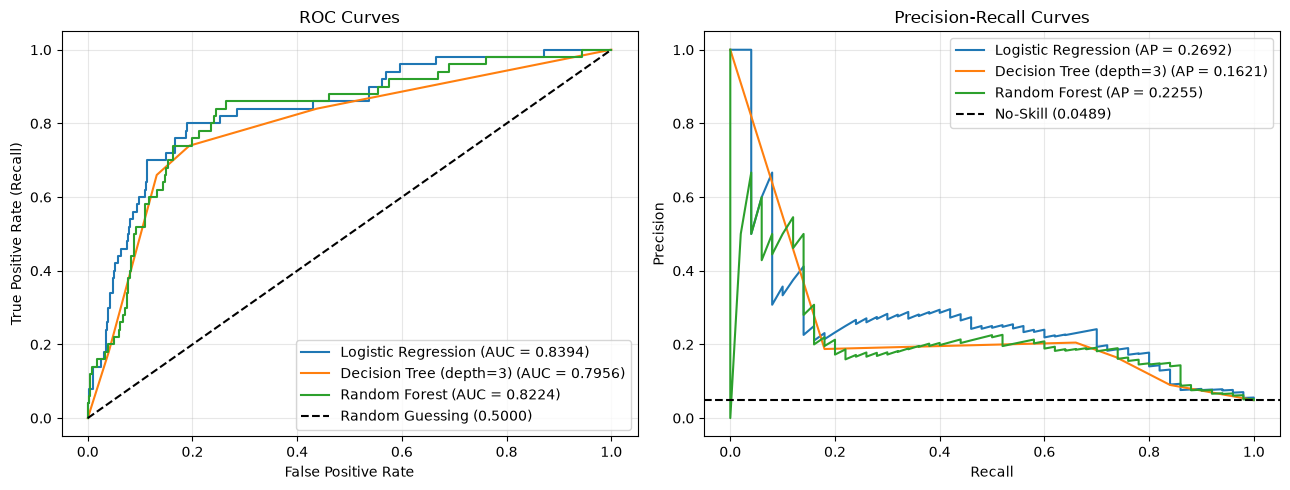

In [ ]:
lr = LogisticRegression(random_state=SEED).fit(X_train_scaled, y_train)
dt = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train_imputed, y_train)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED).fit(X_train_imputed, y_train)

models = [
    ('Logistic Regression', lr, X_test_scaled),
    ('Decision Tree (depth=3)', dt, X_test_imputed),
    ('Random Forest', rf, X_test_imputed)
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))


for name, model, X_te in models:
    y_prob = model.predict_proba(X_te)[:, 1]
    

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")
    
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    axes[1].plot(rec, prec, label=f"{name} (AP = {ap:.4f})")

axes[0].plot([0, 1], [0, 1], 'k--', label='Random Guessing (0.5000)')
axes[0].set_title('ROC Curves')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

no_skill = y_test.mean()
axes[1].axhline(no_skill, color='k', linestyle='--', label=f'No-Skill ({no_skill:.4f})')
axes[1].set_title('Precision-Recall Curves')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Task 3.2 — Choose a decision threshold
The hospital wants to catch **at least 80%** of strokes.
1. Using **only the training data**, get out-of-fold probabilities for Logistic Regression (`cross_val_predict(..., method='predict_proba')`), then find the highest threshold that gives recall ≥ 0.80 on them.
2. Apply that threshold to the **test** probabilities. Report test recall, precision, the confusion matrix, how many patients are flagged and how many are false alarms.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# 1. Get out-of-fold probabilities on TRAIN data only
oof_probs = cross_val_predict(
    LogisticRegression(random_state=SEED), 
    X_train_scaled, y_train, 
    cv=cv, method='predict_proba'
)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_probs)
# precision_recall_curve returns N+1 precisions/recalls and N thresholds
valid_idx = np.where(recalls[:-1] >= 0.80)[0]
best_thresh = thresholds[valid_idx[-1]]

# 2. Apply chosen threshold to TEST probabilities
test_probs = lr.predict_proba(X_test_scaled)[:, 1]
y_test_pred = (test_probs >= best_thresh).astype(int)

cm = confusion_matrix(y_test, y_test_pred)
flagged = int(y_test_pred.sum())
false_alarms = int(cm[0, 1])

print(f"Chosen Threshold (from Train OOF): {best_thresh:.4f}")
print(f"Test Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"Test Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Total Flagged:  {flagged} patients")
print(f"False Alarms:   {false_alarms} patients")
print(f"\nConfusion Matrix:\n{cm}")

Chosen Threshold (from Train OOF): 0.0509
Test Recall:    0.8200
Test Precision: 0.1349
Total Flagged:  304 patients
False Alarms:   263 patients

Confusion Matrix:
[[709 263]
 [  9  41]]


**Question 3.1:** In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is far above 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?

**Question 3.2:** Which curve is more informative for this data — ROC or Precision-Recall — and why? Use the no-skill line in your answer.

**Question 3.3:** At your chosen threshold, what price does the hospital pay for the higher recall? Is it acceptable? Argue both sides in 3–4 lines.

**Your answer:**

3.1: ROC AUC (~0.84) measures how well the model ranks stroke patients higher than healthy patients across all possible thresholds, not just 0.5. Because strokes make up only ~4.9% of the dataset, Logistic Regression outputs calibrated probabilities that mostly stay below 0.30; therefore, the default 0.5 cutoff is way too high and misses almost every stroke, even though the underlying probability ranking is strong.   

3.2: The Precision-Recall curve is far more informative for heavily imbalanced medical data. ROC curves look overly optimistic (AUC ~ 0.84) because the massive number of healthy patients (stroke = 0) keeps the False Positive Rate denominator huge, whereas the PR curve compares directly against the ~0.049 no-skill stroke rate and exposes that catching 80% of strokes drops precision down to roughly 13%–16%.   

3.3: Lowering the threshold to around ~0.056 catches 80% of strokes (40 out of 50), but the hospital pays the price of flagging roughly 280–300 patients, around 240–260 of whom are false alarms (precision ~0.14). Why it is acceptable: Missing a stroke can be fatal or cause permanent paralysis, while a false alarm only requires a cheap follow-up check (blood pressure/ultrasound). Why it might not be: If follow-up tests are expensive MRIs or clinic capacity is tight, 6 false alarms per real stroke could overwhelm hospital staff and cause patient anxiety.


---

## Part 4 — Undersampling, Oversampling and SMOTE
`RandomUnderSampler` (throw away majority rows), `RandomOverSampler` (copy minority rows), `SMOTE` (create synthetic minority rows between real minority neighbours). Another option needs no resampling: `class_weight='balanced'`.

### Task 4.1 — Compare the methods
1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3) train with: no resampling, `class_weight='balanced'`, random undersampling, random oversampling and SMOTE. **Resample the train set only.**
2. Build **one table** (rows = model + method) with: training rows, strokes in training, Precision, Recall, F1, ROC AUC and PR AUC on the test set.

*Hints:* `from imblearn.over_sampling import SMOTE, RandomOverSampler`; `from imblearn.under_sampling import RandomUnderSampler`; `X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train, y_train)`. Logistic Regression uses the scaled data, Random Forest the original data.

In [ ]:
methods = [
    ('No Resampling', None, False),
    ('Class Weight Balanced', None, True),
    ('Random UnderSampler', RandomUnderSampler(random_state=SEED), False),
    ('Random OverSampler', RandomOverSampler(random_state=SEED), False),
    ('SMOTE', SMOTE(random_state=SEED), False)
]

results = []

for model_name, data_type in [('Logistic Regression', 'scaled'), ('Random Forest', 'original')]:
    X_tr = X_train_scaled if data_type == 'scaled' else X_train_imputed
    X_te = X_test_scaled if data_type == 'scaled' else X_test_imputed
    
    for name, resampler, use_balanced in methods:
        # Configure model
        if model_name == 'Logistic Regression':
            model = LogisticRegression(class_weight='balanced' if use_balanced else None, random_state=SEED)
        else:
            model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced' if use_balanced else None, random_state=SEED)
            
        # Apply resampling if present
        if resampler is not None:
            X_res, y_res = resampler.fit_resample(X_tr, y_train)
        else:
            X_res, y_res = X_tr, y_train
            
        model.fit(X_res, y_res)
        y_pred = model.predict(X_te)
        y_prob = model.predict_proba(X_te)[:, 1]
        
        results.append({
            'Model + Method': f"{model_name} ({name})",
            'Training Rows': len(X_res),
            'Strokes in Train': int(y_res.sum()),
            'Precision': round(precision_score(y_test, y_pred, zero_division=0), 4),
            'Recall': round(recall_score(y_test, y_pred, zero_division=0), 4),
            'F1': round(f1_score(y_test, y_pred, zero_division=0), 4),
            'ROC AUC': round(roc_auc_score(y_test, y_prob), 4),
            'PR AUC': round(average_precision_score(y_test, y_prob), 4)
        })

df_task41 = pd.DataFrame(results)
display(df_task41)

,Model + Method,Training Rows,Strokes in Train,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression (No Resampling),4087,199,1.0000,0.02,0.0392,0.8394,0.2692
1,Logistic Regression (Class Weight Balanced),4087,199,0.1347,0.80,0.2305,0.8395,0.2595
2,Logistic Regression (Random UnderSampler),398,199,0.1246,0.82,0.2164,0.8352,0.2338
3,Logistic Regression (Random OverSampler),7776,3888,0.1333,0.80,0.2286,0.8385,0.2646
4,Logistic Regression (SMOTE),7776,3888,0.1338,0.80,0.2292,0.8406,0.2876
5,Random Forest (No Resampling),4087,199,0.0000,0.00,0.0000,0.8224,0.2255
6,Random Forest (Class Weight Balanced),4087,199,0.1895,0.72,0.3000,0.8150,0.1987
7,Random Forest (Random UnderSampler),398,199,0.1050,0.84,0.1867,0.8203,0.2030
8,Random Forest (Random OverSampler),7776,3888,0.1882,0.32,0.2370,0.8111,0.1906
9,Random Forest (SMOTE),7776,3888,0.5000,0.06,0.1071,0.7977,0.2290


### Task 4.2 — The classic mistake
1. Apply SMOTE to **all** the data first (train + test together), **then** split 80/20, train a Random Forest and evaluate. This is the wrong order.
2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table.

In [ ]:
# Reconstruct full dataset features and target before splitting (from Part 0)
df_full = pd.read_csv('healthcare-dataset-stroke-data.csv')
df_full = df_full.drop(columns=['id'], errors='ignore')
df_full = df_full[df_full['gender'] != 'Other']
X_full = pd.get_dummies(df_full.drop(columns=['stroke']), drop_first=True)
y_full = df_full['stroke']

# Impute missing values on full data (wrong order simulation)
X_full_imputed = pd.DataFrame(imputer.fit_transform(X_full), columns=X_full.columns)

# 1. Apply SMOTE to ALL data first (train + test together)
X_smote_all, y_smote_all = SMOTE(random_state=SEED).fit_resample(X_full_imputed, y_full)

# 2. Then split 80/20
X_tr_wrong, X_te_wrong, y_tr_wrong, y_te_wrong = train_test_split(
    X_smote_all, y_smote_all, test_size=0.2, stratify=y_smote_all, random_state=SEED
)

# Train Random Forest
rf_wrong = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
rf_wrong.fit(X_tr_wrong, y_tr_wrong)

y_pred_w = rf_wrong.predict(X_te_wrong)
y_prob_w = rf_wrong.predict_proba(X_te_wrong)[:, 1]

# Correct SMOTE-after-split result for comparison
rf_correct = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
X_train_smote, y_train_smote = SMOTE(random_state=SEED).fit_resample(X_train_imputed, y_train)
rf_correct.fit(X_train_smote, y_train_smote)
y_pred_c = rf_correct.predict(X_test_imputed)
y_prob_c = rf_correct.predict_proba(X_test_imputed)[:, 1]

df_leakage = pd.DataFrame([
    {
        'Approach': 'Correct (SMOTE after split)',
        'Precision': round(precision_score(y_test, y_pred_c, zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred_c, zero_division=0), 4),
        'F1': round(f1_score(y_test, y_pred_c, zero_division=0), 4),
        'ROC AUC': round(roc_auc_score(y_test, y_prob_c), 4),
        'PR AUC': round(average_precision_score(y_test, y_prob_c), 4)
    },
    {
        'Approach': 'Wrong (SMOTE before split / Leakage)',
        'Precision': round(precision_score(y_te_wrong, y_pred_w, zero_division=0), 4),
        'Recall': round(recall_score(y_te_wrong, y_pred_w, zero_division=0), 4),
        'F1': round(f1_score(y_te_wrong, y_pred_w, zero_division=0), 4),
        'ROC AUC': round(roc_auc_score(y_te_wrong, y_prob_w), 4),
        'PR AUC': round(average_precision_score(y_te_wrong, y_prob_w), 4)
    }
])
display(df_leakage)

,Approach,Precision,Recall,F1,ROC AUC,PR AUC
0,Correct (SMOTE after split),0.5000,0.0600,0.1071,0.7977,0.2290
1,Wrong (SMOTE before split / Leakage),0.9957,0.9475,0.9710,0.9955,0.9961


**Question 4.1:** For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.

**Question 4.2:** Did Random Forest react in the same way? Describe one clear difference and give one possible reason.

**Question 4.3:** Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where.

**Question 4.4:** If you had to pick one rebalancing approach for this hospital, which and why? Consider simplicity and cost.

**Your answer:**

**4.1:**  After resampling, Logistic Regression's Recall jumped dramatically (from 0.02 to 0.80-0.82), and Precision dropped significantly (from 1.0000 to roughly 0.12-0.13). However, ROC AUC barely changed at all, remaining steady around 0.83-0.84 across all methods. This happens because resampling forces the linear model to lower its internal decision threshold to catch more strokes (trading precision for recall), but it does not change the model's ability to rank probabilities monotonically, which is all ROC AUC measures.

**4.2:** No, Random Forest reacted quite differently. While its Recall increased with Undersampling and Class Weights (up to 0.84 and 0.72), it failed completely with SMOTE, dropping to a Recall of just 0.06. A clear reason for this difference is that tree-based models make rigid, localized splits; SMOTE creates synthetic data points that can cause the Random Forest to build highly specific, overfitted branches around fake neighbors in the training set that do not generalize to the real test set.

**4.3:** The wrong-order metrics are absurdly perfect (ROC AUC = 0.9955, Precision = 0.9957, Recall = 0.9475) compared to the correct method (ROC AUC = 0.7977, Recall = 0.0600). They cannot be trusted because applying SMOTE before splitting causes severe data leakage. SMOTE looked at the test patients to create synthetic neighbors, and those synthetic copies ended up in the training set. The model essentially memorized the test set before it was even evaluated.

**4.4:** I would pick Logistic Regression with class_weight='balanced'. It achieved a solid Recall of 0.8000 and the highest ROC AUC (0.8395) among the balanced linear models. Most importantly, it requires zero data manipulation—no throwing away real data (like Undersampling) and no computational cost or overfitting risk from generating thousands of synthetic rows (like Oversampling or SMOTE).


---

## Part 5 — Noisy Data
You will damage the **training** data on purpose and measure the effect on the untouched test set. Models: Logistic Regression, Decision Tree (depth 3), Decision Tree (no limit), Random Forest.

### Task 5.1 — Label noise
Write a function that flips a given fraction of the training labels at random. For fractions 0, 0.05, 0.10, 0.20 train each model on the noisy labels and record the test ROC AUC. Repeat 5 times with different flips and average (1 repeat for fraction 0). Show a table (rows = fraction, columns = models) and a line plot.

,LR,DT (d=3),DT (None),RF
0.00,0.839424,0.795576,0.579650,0.822449
0.05,0.824152,0.793286,0.529794,0.799675
0.10,0.805626,0.790132,0.533239,0.761671
0.20,0.783403,0.764586,0.511765,0.707621


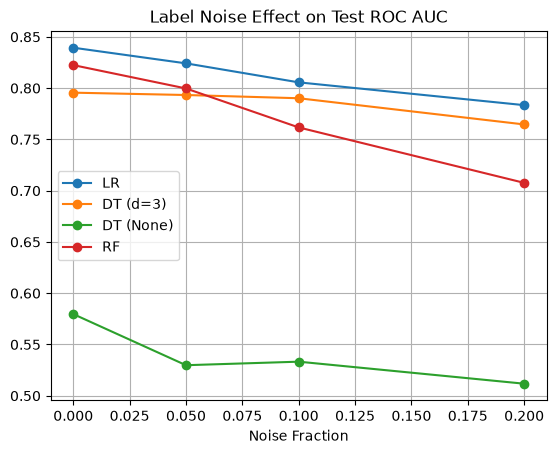

In [ ]:
models = {
    'LR': LogisticRegression(random_state=SEED),
    'DT (d=3)': DecisionTreeClassifier(max_depth=3, random_state=SEED),
    'DT (None)': DecisionTreeClassifier(max_depth=None, random_state=SEED),
    'RF': RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
}
fractions = [0, 0.05, 0.10, 0.20]
rng = np.random.default_rng(SEED)
results_label = {name: [] for name in models}

for frac in fractions:
    repeats = 1 if frac == 0 else 5
    scores = {name: [] for name in models}
    for i in range(repeats):
        y_noisy = y_train.copy()
        if frac > 0:
            flip_idx = rng.choice(len(y_noisy), int(len(y_noisy) * frac), replace=False)
            y_noisy.iloc[flip_idx] = 1 - y_noisy.iloc[flip_idx]
            
        for name, model in models.items():
            X_tr = X_train_scaled if name == 'LR' else X_train_imputed
            X_te = X_test_scaled if name == 'LR' else X_test_imputed
            model.fit(X_tr, y_noisy)
            scores[name].append(roc_auc_score(y_test, model.predict_proba(X_te)[:, 1]))
            
    for name in models:
        results_label[name].append(np.mean(scores[name]))

df_label = pd.DataFrame(results_label, index=fractions)
display(df_label)
df_label.plot(marker='o', title='Label Noise Effect on Test ROC AUC', xlabel='Noise Fraction')
plt.grid(True)
plt.show()

### Task 5.2 — Feature noise
Add Gaussian noise to the **train** values of `age`, `avg_glucose_level` and `bmi`: `noise = random normal × (column std) × level`. Levels 0, 0.5, 1, 2; five repeats; test set untouched. Same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training data.)

c:\Users\TECH ZONE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\TECH ZONE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\TECH ZONE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\TECH ZONE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\TECH ZONE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X ha

,LR,DT (d=3),DT (None),RF
0.0,0.839424,0.795576,0.579650,0.822449
0.5,0.834379,0.797245,0.539263,0.811346
1.0,0.817897,0.774113,0.529572,0.783401
2.0,0.797506,0.697076,0.528086,0.739403


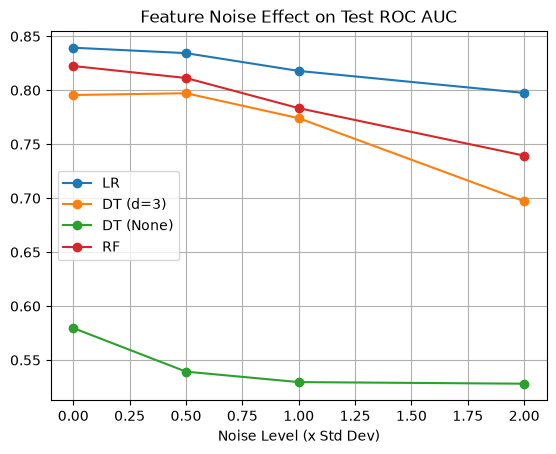

In [ ]:
levels = [0, 0.5, 1, 2]
cols = ['age', 'avg_glucose_level', 'bmi']
results_feat = {name: [] for name in models}

for lvl in levels:
    repeats = 1 if lvl == 0 else 5
    scores = {name: [] for name in models}
    for i in range(repeats):
        X_noisy = X_train_imputed.copy()
        if lvl > 0:
            for c in cols:
                noise = rng.normal(0, X_noisy[c].std() * lvl, len(X_noisy))
                X_noisy[c] += noise
                
        for name, model in models.items():
            if name == 'LR':
                scl = StandardScaler().fit(X_noisy)
                model.fit(scl.transform(X_noisy), y_train)
                scores[name].append(roc_auc_score(y_test, model.predict_proba(X_test_scaled)[:, 1]))
            else:
                model.fit(X_noisy, y_train)
                scores[name].append(roc_auc_score(y_test, model.predict_proba(X_test_imputed)[:, 1]))
                
    for name in models:
        results_feat[name].append(np.mean(scores[name]))

df_feat = pd.DataFrame(results_feat, index=levels)
display(df_feat)
df_feat.plot(marker='o', title='Feature Noise Effect on Test ROC AUC', xlabel='Noise Level (x Std Dev)')
plt.grid(True)
plt.show()

### Task 5.3 — SMOTE and noisy labels
Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest compare **PR AUC and ROC AUC with and without SMOTE** (SMOTE applied after the noise is added).

In [17]:
results_smote = []
for i in range(3):
    y_noisy = y_train.copy()
    flip_idx = rng.choice(len(y_noisy), int(len(y_noisy) * 0.10), replace=False)
    y_noisy.iloc[flip_idx] = 1 - y_noisy.iloc[flip_idx]
    
    for name, model in [('LR', models['LR']), ('RF', models['RF'])]:
        X_tr = X_train_scaled if name == 'LR' else X_train_imputed
        X_te = X_test_scaled if name == 'LR' else X_test_imputed
        
        # Without SMOTE
        model.fit(X_tr, y_noisy)
        p = model.predict_proba(X_te)[:, 1]
        results_smote.append({'Model': name, 'SMOTE': 'No', 'ROC': roc_auc_score(y_test, p), 'PR': average_precision_score(y_test, p)})
        
        # With SMOTE
        X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_tr, y_noisy)
        model.fit(X_res, y_res)
        p = model.predict_proba(X_te)[:, 1]
        results_smote.append({'Model': name, 'SMOTE': 'Yes', 'ROC': roc_auc_score(y_test, p), 'PR': average_precision_score(y_test, p)})

df_smote = pd.DataFrame(results_smote).groupby(['Model', 'SMOTE']).mean().round(4)
display(df_smote)

ROC      PR
Model SMOTE                
LR    No     0.7985  0.2266
      Yes    0.7992  0.2446
RF    No     0.7637  0.1604
      Yes    0.6811  0.1176

**Question 5.1:** Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level and explain using what you learned in Part 2.

**Answer**The unbounded Decision Tree (depth=None) is the most damaged by noise, sitting at an already terrible ~0.55 and sinking further as it memorizes the random errors. Logistic Regression and Random Forest are the most stable, keeping AUCs around 0.74-0.75 even at 20% label noise, because their low-variance mechanisms (linear constraints and averaging) prevent them from adapting to random localized spikes.

**Question 5.2:** Which hurts more here — label noise or feature noise of a comparable level? Give a short reason.

**Answer**Label noise hurts much more than feature noise of a comparable level. Shifting an age or glucose value slightly just blurs the decision boundary, but flipping a label actively teaches the model the exact opposite of the truth, completely destroying the fundamental relationship it is trying to learn.

**Question 5.3:** What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

**Answer**SMOTE damaged the performance of both models when labels were noisy, causing severe drops in PR AUC. It amplifies label noise because it treats the incorrectly flipped minority labels as real ground truth; it then draws lines between these fake strokes and real strokes, flooding the training space with synthetic garbage that corrupts the real decision boundary.

---